In [1]:
import xarray as xr
import numpy as np
import scipy.sparse as sps
import cftime
import datetime
import os
import matplotlib as mpl
import matplotlib.pyplot as plt
import cartopy
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import matplotlib.units as munits
from matplotlib.dates import ConciseDateConverter
munits.registry[cftime.DatetimeNoLeap] = ConciseDateConverter()
munits.registry[cftime.datetime] = ConciseDateConverter()

## Get POP grid

In [2]:
fgrd = '/glade/work/fredc/cesm/grid/POP/POP_tx0.1v2_grid.nc'
dsg = xr.open_dataset(fgrd)

# Grid Metrics
tlon = dsg.TLONG.drop_vars(['ULONG','ULAT'])
tlon.data = np.where(np.greater_equal(tlon, min(tlon[:,0])), tlon-360., tlon)
tlat = dsg.TLAT.drop_vars(['ULONG','ULAT'])
tarea = dsg['TAREA'].drop_vars(['ULONG','ULAT'])
tmask = dsg['tmask'].isel(z_t=0).drop_vars(['ULONG','ULAT'])

## Get POP SST

In [3]:
fdir = '/glade/derecho/scratch/fredc/archive/'
case = 'b.e13.B1950C5.ne120_t12.cesm-ihesp-hires1.0.46.4xCO2.test'

fpath = '{}/{}/ocn/hist/{}.pop.h.0*.nc'.format(fdir,case,case)

def preprocess(ds):
    return ds[["TEMP"]].isel(z_t=0)

ds = xr.open_mfdataset(fpath,
                       parallel=True, # use dask to read in parallel
                       combine="nested",  # combine files in order provided
                       concat_dim="time",  # concatentate files along time dimension
                       data_vars="minimal",  # only concatentate data variables with "time" dimension
                       coords="minimal",  # same as above for coordinate variables
                       compat="override",
                       preprocess=preprocess, # run this function on each dataset first before combining
                       chunks={"time": 12, 'nlon':200, 'nlat':200}, # choose simple
                       )
ds['time'] = ds.time - datetime.timedelta(15) #middle of the month
sst = ds.TEMP
sst = sst.drop_vars(['ULONG','ULAT'])
sst['TLONG'] = tlon
sst['TLAT'] = tlat

In [4]:
msst = sst.mean('time')

## Plot

In [5]:
from matplotlib import colors
cmap = np.loadtxt('/glade/u/home/fredc/python/cmap/NCL_default.cmap')
cmap = colors.ListedColormap(cmap)

Text(0.5, 1.0, 'POP mean Sea Surface Temperature')

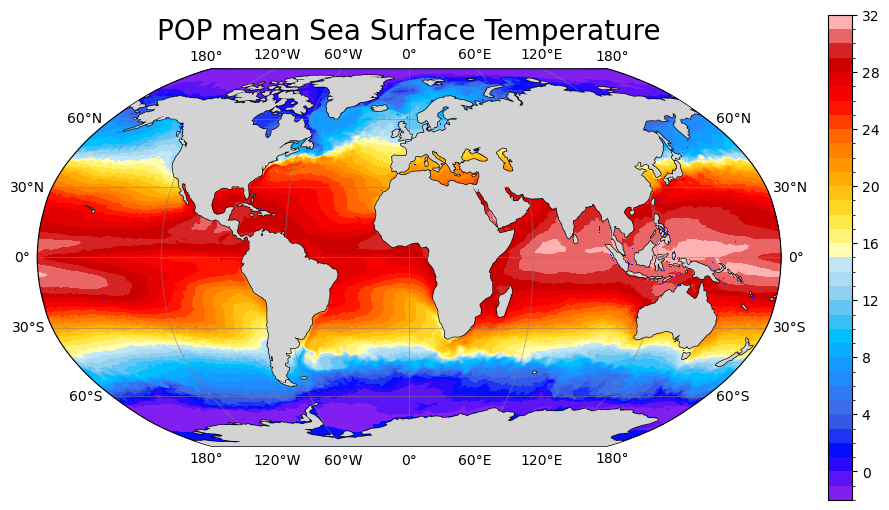

In [6]:
plt.figure(figsize=(12,9))

# the central_longitude parameter tells the projection where to be centered for this axes
ax = plt.axes(projection=ccrs.Robinson(central_longitude=0))
gl = ax.gridlines(linewidth=0.75, color='gray', alpha=0.5, linestyle='-', draw_labels=True)

# add geographic information
ax.add_feature(cartopy.feature.LAND, fc='lightgray', zorder=10)
ax.coastlines(resolution='110m')  # looks better with resolution='10m'
#ax.add_feature(cartopy.feature.BORDERS, linestyle='-', lw=.1)
#ax.add_feature(cartopy.feature.RIVERS)

cmin=-2
cmax=32
n=35
clevs=np.linspace(cmin,cmax,n)
norm=mpl.colors.BoundaryNorm(clevs, ncolors=cmap.N)

im = ax.pcolormesh(msst.TLONG, msst.TLAT, msst*tmask.where(tmask==1), transform=ccrs.PlateCarree(), cmap=cmap, norm=norm)
plt.colorbar(im, shrink=0.7)

plt.title('POP mean Sea Surface Temperature', fontsize=20)